# PhysAnchor-MJO-AE — problem setup (a reconstruction baseline matched to V-JEPA)

A **reconstruction autoencoder** (the method of arXiv:2512.22144, *"The Complete Anatomy
of the MJO Revealed by AI"*) that learns a per-day latent of the **Madden–Julian
Oscillation (MJO)** by reconstructing the target day of a short 3-day clip of tropical
anomaly maps.  The per-day latents are then clustered into a six-phase MJO **anatomy**
(SOM 4×2 → 6 canonical phases, validated by k-means) and turned into a decoupled
**pattern-correlation monitoring index** (location + intensity).

**This is built as a head-to-head baseline for my V-JEPA**, so two things are pinned to be
identical and only the *objective* differs:

| pinned to match V-JEPA | value |
|---|---|
| encoder | the **same** `jepa.models.encoder.STViTBackbone` (same patch/tubelet, depth, width) |
| latent dimension | the **same** `embed_dim = 192` — **not** the paper's 1024-d latent |
| data + dataloader | the **same** `jepa.data.dataset.MJOSequence` over the **same** anomaly cache |
| pooling | the same current-day token mean pool as V-JEPA's `embed_clip` |

**What changes vs V-JEPA:** the objective.  V-JEPA predicts a *masked latent* (EMA target,
predictor, no pixels); this AE reconstructs the *target-day pixels* with an MSE loss — no
masking, no EMA, no predictor.  Comparing the two latent spaces therefore isolates the
effect of *reconstruction vs latent-prediction* with everything else held fixed.

In [1]:
import os, sys
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt

ROOT = "/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO"
sys.path.insert(0, ROOT)

from jepa.data.dataset import MJOSequence, SyntheticSequence
from jepa.models.encoder import build_encoder, STViTBackbone
from AE.models.decoder import build_decoder
from AE.models.ae import build_ae

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
CFG = yaml.safe_load(open(os.path.join(ROOT, "AE/config_ae.yaml")))
VJEPA = yaml.safe_load(open(os.path.join(ROOT, "jepa/config_vjepa.yaml")))
print("config sections:", list(CFG))

/glade/work/weidong/conda-envs/myenv/lib/python3.10/site-packages/pyramid/path.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


config sections: ['data', 'encoder', 'decoder', 'method', 'train']


## 1. Configuration — and the two hard constraints, verified

`AE/config_ae.yaml` copies the `data:` and `encoder:` blocks **verbatim** from
`jepa/config_vjepa.yaml`, and pins `method.latent_dim` to `encoder.embed_dim`.  The cell
below asserts both: the data block matches V-JEPA byte-for-byte, and the AE latent dim
equals the V-JEPA encoder dim.

In [2]:
D, E, DEC, M, TR = CFG["data"], CFG["encoder"], CFG["decoder"], CFG["method"], CFG["train"]

assert D == VJEPA["data"],     "data block must match V-JEPA verbatim"
assert E == VJEPA["encoder"],  "encoder block must match V-JEPA verbatim"
assert M["latent_dim"] == E["embed_dim"] == VJEPA["encoder"]["embed_dim"], "latent dim must match"

print(f"variables   : olr, u850, u200   (WH04 anomalies, full 2-D maps — same cache as V-JEPA)")
print(f"grid        : {E['img_size']} (lat x lon) @ 2.5deg, {D['lat_band']} band")
print(f"clip        : T={E['num_frames']} days (t-2,t-1,t), patch {E['patch_size']} (lat,lon)")
print(f"train years : {D['train_years']}   val years: {D['val_years']}  (split by anchor day)")
print(f"encoder     : STViTBackbone dim={E['embed_dim']} depth={E['depth']} heads={E['num_heads']}")
print(f"decoder     : dim={DEC['dec_dim']} depth={DEC['depth']} (small, mirrors encoder -> pixels)")
print(f"objective   : reconstruct day '{M['target_day']}', loss={M['loss_type']}, pool={M['pool']}")
print(f"LATENT DIM  : {M['latent_dim']}  ==  V-JEPA embed_dim {VJEPA['encoder']['embed_dim']}  "
      f"(paper uses 1024; overridden)")

variables   : olr, u850, u200   (WH04 anomalies, full 2-D maps — same cache as V-JEPA)
grid        : [13, 144] (lat x lon) @ 2.5deg, [15.0, -15.0] band
clip        : T=3 days (t-2,t-1,t), patch [1, 8] (lat,lon)
train years : [1979, 2014]   val years: [2015, 2020]  (split by anchor day)
encoder     : STViTBackbone dim=192 depth=6 heads=4
decoder     : dim=128 depth=4 (small, mirrors encoder -> pixels)
objective   : reconstruct day 'last', loss=mse, pool=current
LATENT DIM  : 192  ==  V-JEPA embed_dim 192  (paper uses 1024; overridden)


## 2. Data — identical samples to V-JEPA

The AE reads the **same** anomaly cache (`data/anom_st`) through the **same** `MJOSequence`
loader.  Each sample is a 3-day "video" of OLR/U850/U200 anomalies `(C=3, T=3, 13, 144)`;
the AE reconstructs the **target day** (day `t`, the last frame — the paper's day-`t`
reconstruction).  Enhanced convection is **blue** (negative OLR anomaly) and drifts east.

In [3]:
cache = D["cache_dir"]
have_cache = os.path.exists(os.path.join(cache, "anom.npy"))
if have_cache:
    anom = np.load(os.path.join(cache, "anom.npy"), mmap_mode="r")
    dates = np.load(os.path.join(cache, "dates.npy")).astype("datetime64[D]")
    stats = np.load(os.path.join(cache, "stats.npz"))
    print(f"anomaly cache: {anom.shape}  {dates[0]} -> {dates[-1]}")
    print(f"  lat {stats['lat'][0]:.1f}..{stats['lat'][-1]:.1f}  lon {stats['lon'][0]:.1f}..{stats['lon'][-1]:.1f}E")
else:
    print("cache not found — run: python -m jepa.data.preprocess --config jepa/config_vjepa.yaml")

anomaly cache: (15222, 3, 13, 144)  1979-04-30 -> 2020-12-31
  lat 15.0..-15.0  lon 0.0..357.5E


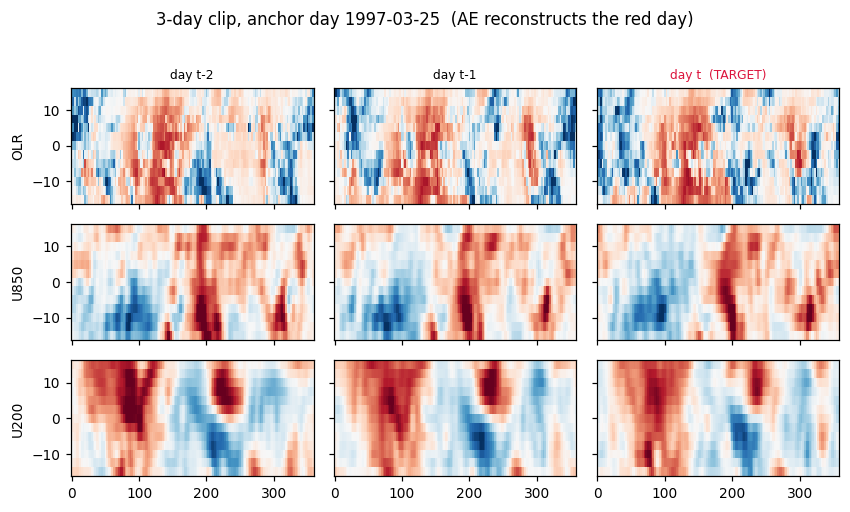

In [4]:
def draw_clip(clip, lat, lon, target_t, title=""):
    """clip: (C,T,H,W) standardized anomalies; highlight the reconstruction target day."""
    C, T, H, W = clip.shape
    names = ["OLR", "U850", "U200"]
    fig, axes = plt.subplots(C, T, figsize=(2.6*T, 1.5*C), sharex=True, sharey=True)
    for c in range(C):
        vmax = np.nanpercentile(np.abs(clip[c]), 99) or 1.0
        for t in range(T):
            ax = axes[c, t]
            ax.pcolormesh(lon, lat, clip[c, t], cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
            if c == 0:
                lab = f"day t{['-2','-1',''][t]}" + ("  (TARGET)" if t == target_t else "")
                ax.set_title(lab, fontsize=8, color=("crimson" if t == target_t else "black"))
            if t == 0: ax.set_ylabel(names[c])
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

if have_cache:
    seq = MJOSequence(cache, list(range(D["year_start"], D["year_end"]+1)), seq_len=D["seq_len"])
    k = len(seq)//3
    try:
        import pandas as pd
        rmm = pd.read_csv(D["rmm_csv"], parse_dates=["time"])
        strong = rmm.loc[rmm["amplitude"].idxmax(), "time"]
        k = int(np.argmin(np.abs(seq.anchor_dates() - np.datetime64(strong, "D"))))
    except Exception as e:
        print("(rmm pick skipped:", e, ")")
    s = seq[k]
    target_t = E["num_frames"]-1 if M["target_day"]=="last" else E["num_frames"]//2
    draw_clip(s["x"].numpy(), stats["lat"], stats["lon"], target_t,
              title=f"3-day clip, anchor day {seq.anchor_dates()[k]}  (AE reconstructs the red day)")

## 3. Architecture & reconstruction schematic

```
  clip (B,3,T=3,13,144)
        │
        ▼   jepa.models.STViTBackbone           ← SAME encoder as V-JEPA
   patch tokens (B, 702, 192)
        │   pool current-day tokens (mean)       ← SAME pooling as V-JEPA embed_clip
        ▼
   latent z (B, 192)                              ← 192 == V-JEPA embed_dim (NOT 1024)
        │   SpatialDecoder (small transformer)
        ▼   per-patch head + un-patchify
   recon day-t field (B, 3, 13, 144)
        │
        ▼   MSE( recon , true day-t )             ← the only objective
```

The latent is a single 192-d vector per clip — the "MJO fingerprint" used downstream.  The
decoder exists only to drive the reconstruction loss; it is deliberately small and swappable,
so the **encoder** is what stays identical to V-JEPA.

In [5]:
enc = build_encoder(E)
dec = build_decoder(E, DEC, M["latent_dim"])
model = build_ae(enc, dec, M)

assert isinstance(model.encoder, STViTBackbone), "encoder must be the shared STViTBackbone"
assert model.encoder.embed_dim == M["latent_dim"], "latent dim must equal encoder embed_dim"

def nparams(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"encoder (shared w/ V-JEPA): {nparams(model.encoder)/1e6:.2f} M  dim={model.encoder.embed_dim}")
print(f"decoder (AE-only, small)  : {nparams(model.decoder)/1e6:.2f} M")
print(f"total trainable           : {nparams(model)/1e6:.2f} M  (no EMA, no predictor)")

# one forward pass (real clip if cache present, else synthetic)
if have_cache:
    xb = torch.stack([seq[i]["x"] for i in range(8)])
else:
    sy = SyntheticSequence(n=8, shape=(E["in_chans"], E["num_frames"], *E["img_size"]))
    xb = torch.stack([sy[i]["x"] for i in range(8)])
loss, st = model(xb)
z = model.encode_latent(xb)
print(f"\nlatent z: {tuple(z.shape)} (B, 192)   forward MSE={st['loss']:.4f}  "
      f"rel_mse={st['rel_mse']:.3f} (<1 beats predict-zero)")

encoder (shared w/ V-JEPA): 2.67 M  dim=192
decoder (AE-only, small)  : 0.82 M
total trainable           : 3.50 M  (no EMA, no predictor)

latent z: (8, 192) (B, 192)   forward MSE=3.4534  rel_mse=3.851 (<1 beats predict-zero)


### Reconstruction at init (untrained) vs target

Before training the reconstruction is meaningless — this just confirms the decoder wiring
produces a day-`t`-shaped field.  After training (`best.tar`) rerun this on the trained model
to see the reconstruction track the true convective/wind anomaly pattern.

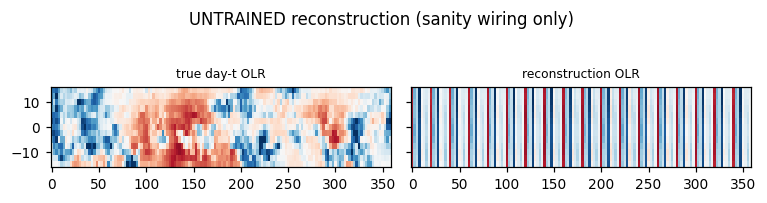

In [6]:
@torch.no_grad()
def show_recon(model, x1, lat, lon, target_t, ch=0, title=""):
    recon = model.decoder(model.encode_latent(x1[None]))[0]   # (C,H,W)
    true = x1[:, target_t]                                     # (C,H,W)
    names = ["OLR","U850","U200"]
    fig, ax = plt.subplots(1, 2, figsize=(7, 1.7), sharey=True)
    vmax = np.nanpercentile(np.abs(true[ch].numpy()), 99) or 1.0
    ax[0].pcolormesh(lon, lat, true[ch], cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
    ax[0].set_title(f"true day-t {names[ch]}", fontsize=8)
    ax[1].pcolormesh(lon, lat, recon[ch], cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
    ax[1].set_title(f"reconstruction {names[ch]}", fontsize=8)
    fig.suptitle(title, y=1.05); plt.tight_layout(); plt.show()

if have_cache:
    show_recon(model, seq[k]["x"], stats["lat"], stats["lon"], target_t, ch=0,
               title="UNTRAINED reconstruction (sanity wiring only)")

## 4. How to train and run downstream

```bash
cd /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO

# 0. shared anomaly cache (already built for V-JEPA; only if missing)
python -m jepa.data.preprocess --config jepa/config_vjepa.yaml

# 1. quick CPU smoke test (synthetic clips; asserts reconstruction loss falls)
python AE/train_ae.py --config AE/config_ae.yaml --smoke

# 2. single-GPU training (AMP, cosine LR, best/last checkpoints, resume) — or: qsub AE/submit_ae.pbs
python AE/train_ae.py --config AE/config_ae.yaml

# 3. downstream (paper science)
python -m AE.downstream.extract  --ckpt runs/ae/best.tar   # daily latents
python -m AE.downstream.phases   --ckpt runs/ae/best.tar   # SOM 4x2 -> 6 + k-means k=6 anatomy
python -m AE.downstream.monitor  --ckpt runs/ae/best.tar   # decoupled location+intensity index vs RMM
python -m AE.downstream.compare  --ae_ckpt runs/ae/best.tar --jepa_dir runs/vjepa   # AE vs V-JEPA
```

**Assumptions (this setup):** 2.5° grid, 15°N–15°S band (13 lat × 144 lon), full periodic
longitude; OLR/U850/U200 WH04 anomalies (seasonal harmonics + 120-day mean, no bandpass —
the V-JEPA data block, reused verbatim), per-variable standardized on the training years;
clips of 3 consecutive days; reconstruct day `t`; train 1979–2014 / val 2015–2020 split by
anchor day; **latent dim 192 == V-JEPA**; current-day pooling.  The paper's 30°E–210°E local
sector is applied in the downstream pattern-correlation monitor (`AE/downstream/monitor.py`),
while the encoder sees the full global field so its input samples are identical to V-JEPA's.